# Task 2: Near-Duplicate Document Detection at Scale

**Goal.** Return every unordered pair `(id1, id2)`, `id1 < id2`, whose Jaccard similarity on word 5-gram shingles is **≥ 0.8**, for 112,571 documents, in < 15 min and < 12 GB on Colab free CPU.

**Plan (stages).**
1. **Shingling:** `text.split()` → word ids → one 64-bit hash per 5-word window (position-rotated XOR of random per-word values). Documents with < 5 words get exactly one shingle (the whole sequence). Each document becomes a sorted, unique `uint64` array.
2. **MinHash:** `k = b·r = 100` hash functions `h(x) = a·x + b (mod 2^64)`; signature = minimum per document, computed for all documents at once with `np.minimum.reduceat`.
3. **LSH banding:** `b = 20` bands × `r = 5` rows. Documents whose 5 values in some band are identical land in the same bucket → candidate pair.
4. **Exact verification:** size filter (`J ≤ min/max`), then exact Jaccard with `np.intersect1d`. Only pairs with J ≥ 0.8 are returned, so false positives come only from 64-bit hash collisions (negligible).

Only NumPy, pandas, matplotlib and the standard library are used; the method is written from scratch.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = "/content/drive/MyDrive/RC3 AI Hackathon/lsh_task"   # adjust if your shortcut path differs

import time, math, statistics
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

docs = pd.read_csv(f"{DATA_DIR}/docs.csv", dtype=str, keep_default_na=False)
dev = pd.read_csv(f"{DATA_DIR}/dev_docs.csv", dtype=str, keep_default_na=False)
truth = pd.read_csv(f"{DATA_DIR}/dev_ground_truth.csv", dtype=str)
print(docs.shape, dev.shape, truth.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(112571, 2) (5059, 2) (341, 3)


## 1. Core method

In [4]:
"""Task 2 core: shingles -> MinHash -> LSH banding -> exact Jaccard verification.

Only the standard library and NumPy are used.
"""
import time
import numpy as np

K_SHINGLE = 5
NUM_BANDS = 20      # b
ROWS = 5            # r   -> k = b * r MinHash values per document
SEED = 12345
MASK64 = (1 << 64) - 1


def _rotl(x, k):
    """64-bit rotate-left on a uint64 array."""
    if k == 0:
        return x
    return (x << np.uint64(k)) | (x >> np.uint64(64 - k))


def build_shingles(texts, seed=SEED):
    """Return (H, offsets): H is the concatenation of every document's sorted,
    unique 64-bit shingle hashes; document i owns H[offsets[i]:offsets[i+1]]."""
    rng = np.random.default_rng(seed)
    vocab = {}
    word_ids = []
    lengths = np.empty(len(texts), dtype=np.int64)
    for i, t in enumerate(texts):                       # word -> integer id
        ids = [vocab.setdefault(w, len(vocab)) for w in t.split()]
        word_ids.append(ids)
        lengths[i] = len(ids)
    # random 64-bit value per distinct word (tabulation hashing)
    table = rng.integers(0, 2**63, size=len(vocab) + 1, dtype=np.uint64) * np.uint64(2) + np.uint64(1)
    allw = np.fromiter((w for ids in word_ids for w in ids), dtype=np.int64, count=int(lengths.sum()))
    del word_ids
    tw = table[allw]
    del allw
    starts = np.zeros(len(texts) + 1, dtype=np.int64)
    np.cumsum(lengths, out=starts[1:])

    pieces, sizes = [], np.empty(len(texts), dtype=np.int64)
    # 5-gram hash = XOR of the word values rotated by their position in the gram
    n_all = len(tw)
    if n_all >= K_SHINGLE:
        g = tw[: n_all - K_SHINGLE + 1].copy()
        for j in range(1, K_SHINGLE):
            g ^= _rotl(tw[j: n_all - K_SHINGLE + 1 + j], 13 * j)
    else:
        g = np.empty(0, dtype=np.uint64)
    short_salt = np.uint64(0x9E3779B97F4A7C15)
    for i in range(len(texts)):
        s, L = starts[i], lengths[i]
        if L >= K_SHINGLE:
            h = np.unique(g[s: s + L - K_SHINGLE + 1])   # grams fully inside doc i
        else:
            # fewer than 5 words: one shingle = the whole word sequence
            v = np.uint64((int(L) * 0x9E3779B97F4A7C15) & MASK64)
            for j in range(L):
                v ^= _rotl(tw[s + j: s + j + 1], (7 * j + 3) % 64)[0]
            h = np.array([v ^ short_salt], dtype=np.uint64)
        pieces.append(h)
        sizes[i] = len(h)
    offsets = np.zeros(len(texts) + 1, dtype=np.int64)
    np.cumsum(sizes, out=offsets[1:])
    return np.concatenate(pieces), offsets


def minhash(H, offsets, k, seed=SEED):
    """k MinHash values per document using h(x) = a*x + b (mod 2^64)."""
    rng = np.random.default_rng(seed + 1)
    a = rng.integers(0, 2**63, size=k, dtype=np.uint64) * np.uint64(2) + np.uint64(1)
    b = rng.integers(0, 2**63, size=k, dtype=np.uint64)
    sig = np.empty((len(offsets) - 1, k), dtype=np.uint64)
    starts = offsets[:-1]
    for j in range(k):
        v = H * a[j]
        v += b[j]
        sig[:, j] = np.minimum.reduceat(v, starts)
    return sig


def lsh_candidates(sig, bands, rows, seed=SEED):
    """Pairs (i, j), i < j, that agree on all rows of at least one band."""
    n = sig.shape[0]
    rng = np.random.default_rng(seed + 2)
    mult = rng.integers(0, 2**63, size=rows, dtype=np.uint64) * np.uint64(2) + np.uint64(1)
    cand = []
    biggest = 0
    for bi in range(bands):
        block = sig[:, bi * rows:(bi + 1) * rows]
        key = (block * mult).sum(axis=1, dtype=np.uint64)  # band -> one bucket key
        order = np.argsort(key, kind="stable")
        ks = key[order]
        brk = np.flatnonzero(np.diff(ks)) + 1
        bstart = np.concatenate(([0], brk))
        bend = np.concatenate((brk, [n]))
        sz = bend - bstart
        biggest = max(biggest, int(sz.max()))
        for size in np.unique(sz[sz >= 2]):                 # vectorised per bucket size
            st = bstart[sz == size]
            members = order[st[:, None] + np.arange(size)]  # (#buckets, size)
            iu, ju = np.triu_indices(size, 1)
            a_ = members[:, iu].ravel()
            b_ = members[:, ju].ravel()
            cand.append(np.minimum(a_, b_) * n + np.maximum(a_, b_))
    if not cand:
        return np.empty((0, 2), dtype=np.int64), biggest
    codes = np.unique(np.concatenate(cand))
    return np.stack((codes // n, codes % n), axis=1), biggest


def verify(pairs, H, offsets, threshold):
    """Exact Jaccard on the candidate pairs. Returns (kept pairs, their J)."""
    sizes = np.diff(offsets)
    si, sj = sizes[pairs[:, 0]], sizes[pairs[:, 1]]
    # size filter: J <= min/max, so min/max < threshold means J < threshold
    ok = np.minimum(si, sj) >= threshold * np.maximum(si, sj)
    pairs = pairs[ok]
    keep, js = [], []
    for i, j in pairs:
        a = H[offsets[i]:offsets[i + 1]]
        b = H[offsets[j]:offsets[j + 1]]
        inter = len(np.intersect1d(a, b, assume_unique=True))
        jac = inter / (len(a) + len(b) - inter)
        if jac >= threshold:
            keep.append((i, j))
            js.append(jac)
    return keep, js


def find_similar_pairs(ids, texts, threshold=0.8, bands=NUM_BANDS, rows=ROWS,
                       timings=None, stats=None):
    t0 = time.perf_counter()
    H, offsets = build_shingles(texts)
    t1 = time.perf_counter()
    sig = minhash(H, offsets, bands * rows)
    t2 = time.perf_counter()
    cand, biggest = lsh_candidates(sig, bands, rows)
    t3 = time.perf_counter()
    keep, _ = verify(cand, H, offsets, threshold)
    t4 = time.perf_counter()
    out = set()
    for i, j in keep:
        a, b = ids[i], ids[j]
        out.add((a, b) if a < b else (b, a))
    if timings is not None:
        timings.update(shingle=t1 - t0, minhash=t2 - t1, lsh=t3 - t2, verify=t4 - t3, total=t4 - t0)
    if stats is not None:
        stats.update(n_shingles=len(H), n_candidates=len(cand), biggest_bucket=biggest, n_pairs=len(out))
    return out

## 2. Reference exact Jaccard (straight from the definition)
Used to check results and for brute force. It works on the raw string shingles, independent of my hashing, so it also tests the hashing.

In [5]:
def shingle_set(text):
    w = text.split()
    if len(w) < 5:
        return frozenset([' '.join(w)])
    return frozenset(' '.join(w[i:i+5]) for i in range(len(w) - 4))

def exact_jaccard(t1, t2):
    a, b = shingle_set(t1), shingle_set(t2)
    inter = len(a & b)
    return inter / (len(a) + len(b) - inter)

def brute_force_pairs(ids, texts, threshold=0.8):
    S = [shingle_set(t) for t in texts]
    out = set()
    for i in range(len(S)):
        a = S[i]
        for j in range(i + 1, len(S)):
            b = S[j]
            x = len(a & b)
            if x / (len(a) + len(b) - x) >= threshold:
                out.add((ids[i], ids[j]) if ids[i] < ids[j] else (ids[j], ids[i]))
    return out

# sanity: short documents and identical texts
print(exact_jaccard("a b c", "a b c"), exact_jaccard("a b c", "a b c d"), exact_jaccard("", ""))

1.0 0.0 1.0


## 3. Correctness on the dev set

In [6]:
dev_ids, dev_texts = dev.id.tolist(), dev.text.tolist()
text_of = dict(zip(dev_ids, dev_texts))
T = set(zip(truth.id1, truth.id2))
tm, st = {}, {}
P = find_similar_pairs(dev_ids, dev_texts, 0.8, timings=tm, stats=st)
tp = len(P & T)
prec = tp / len(P) if P else 0.0
rec = tp / len(T)
f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
print(f"found={len(P)}  true={len(T)}  TP={tp}")
print(f"precision={prec:.4f}  recall={rec:.4f}  F1={f1:.4f}")
print("stats:", st)
print("stage times (s):", {k: round(v, 3) for k, v in tm.items()})

missed, wrong = sorted(T - P), sorted(P - T)
print(f"\nmissed pairs: {len(missed)}")
for a, b in missed[:5]:
    print(f"  {a} {b}  J={exact_jaccard(text_of[a], text_of[b]):.4f}")
print(f"wrong pairs: {len(wrong)}")
for a, b in wrong[:5]:
    print(f"  {a} {b}  J={exact_jaccard(text_of[a], text_of[b]):.4f}")

found=341  true=341  TP=341
precision=1.0000  recall=1.0000  F1=1.0000
stats: {'n_shingles': 3358703, 'n_candidates': 563, 'biggest_bucket': 4, 'n_pairs': 341}
stage times (s): {'shingle': 2.573, 'minhash': 1.222, 'lsh': 0.036, 'verify': 0.025, 'total': 3.856}

missed pairs: 0
wrong pairs: 0


**Near-misses (pairs just below 0.8).** No missed or wrong pairs means there is nothing to explain from the dev run, so the most instructive cases are the hardest *negatives*: candidate pairs that LSH examined and exact verification rejected. They show why verification is needed.

In [7]:
H_d, off_d = build_shingles(dev_texts)
sig_d = minhash(H_d, off_d, NUM_BANDS * ROWS)
cand_d, _ = lsh_candidates(sig_d, NUM_BANDS, ROWS)
rows_ = []
for i, j in cand_d:
    J = exact_jaccard(dev_texts[i], dev_texts[j])
    if J < 0.8:
        rows_.append((dev_ids[i], dev_ids[j], round(J, 4)))
rej = pd.DataFrame(rows_, columns=["id1", "id2", "jaccard"]).sort_values("jaccard", ascending=False)
print(f"{len(cand_d)} candidates examined, {len(rej)} rejected by exact verification")
rej.head(8)

563 candidates examined, 222 rejected by exact verification


,id1,id2,jaccard
94,dev001215,dev001329,0.7992
55,dev000531,dev001410,0.7990
158,dev002300,dev004255,0.7986
166,dev002465,dev004612,0.7986
2,dev000017,dev002927,0.7951
87,dev001144,dev004445,0.7897
15,dev000114,dev003007,0.7867
31,dev000283,dev000860,0.7855


## 4. Parameter justification: probability that a pair is examined
A pair with Jaccard J agrees on one MinHash value with probability J, so it agrees on a whole band with probability Jʳ and is examined with probability **P(J) = 1 − (1 − Jʳ)ᵇ**.
To measure this on the dev set I need pairs across the whole J range. I collect pairs with a very loose banding (b=50, r=2, which catches almost every pair with J ≳ 0.2), compute their exact J, and check whether the chosen (b=20, r=5) scheme examines them.

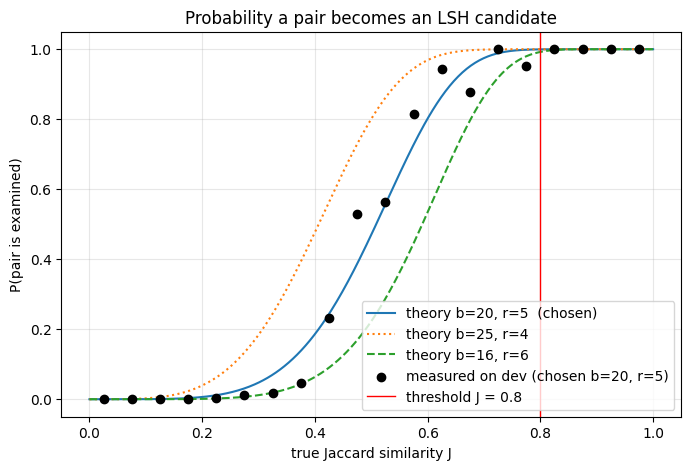

b=20 r=5:  P(0.8)=0.99964  P(0.7)=0.975  P(0.5)=0.470  P(0.3)=0.0475
b=25 r=4:  P(0.8)=1.00000  P(0.7)=0.999  P(0.5)=0.801  P(0.3)=0.1840
b=16 r=6:  P(0.8)=0.99228  P(0.7)=0.865  P(0.5)=0.223  P(0.3)=0.0116
    J_bin_center  pairs  measured_P
0          0.025     88       0.000
1          0.075    806       0.000
2          0.125   2052       0.000
3          0.175   2050       0.001
4          0.225   1090       0.005
5          0.275    407       0.012
6          0.325     53       0.019
7          0.375     42       0.048
8          0.425     60       0.233
9          0.475     53       0.528
10         0.525     55       0.564
11         0.575     38       0.816
12         0.625     35       0.943
13         0.675     33       0.879
14         0.725     20       1.000
15         0.775     21       0.952
16         0.825     33       1.000
17         0.875     71       1.000
18         0.925    103       1.000
19         0.975    134       1.000


In [8]:
cand_loose, _ = lsh_candidates(minhash(H_d, off_d, 100, seed=999), 50, 2, seed=999)
chosen = set(map(tuple, cand_d.tolist()))
Js, hit = [], []
for i, j in cand_loose:
    Js.append(exact_jaccard(dev_texts[i], dev_texts[j]))
    hit.append((i, j) in chosen)
Js, hit = np.array(Js), np.array(hit)

bins = np.linspace(0, 1, 21)
centers, frac, cnt = [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (Js >= lo) & (Js < hi) if hi < 1 else (Js >= lo)
    if m.sum() >= 3:
        centers.append((lo + hi) / 2); frac.append(hit[m].mean()); cnt.append(int(m.sum()))

x = np.linspace(0, 1, 400)
plt.figure(figsize=(8, 5))
for b_, r_, sty in [(20, 5, '-'), (25, 4, ':'), (16, 6, '--')]:
    plt.plot(x, 1 - (1 - x**r_)**b_, sty, label=f"theory b={b_}, r={r_}" + ("  (chosen)" if (b_, r_) == (20, 5) else ""))
plt.scatter(centers, frac, color='k', zorder=3, label="measured on dev (chosen b=20, r=5)")
plt.axvline(0.8, color='r', lw=1, label="threshold J = 0.8")
plt.xlabel("true Jaccard similarity J"); plt.ylabel("P(pair is examined)")
plt.title("Probability a pair becomes an LSH candidate"); plt.legend(); plt.grid(alpha=.3)
plt.show()
for b_, r_ in [(20, 5), (25, 4), (16, 6)]:
    p = lambda J: 1 - (1 - J**r_)**b_
    print(f"b={b_:2d} r={r_}:  P(0.8)={p(0.8):.5f}  P(0.7)={p(0.7):.3f}  P(0.5)={p(0.5):.3f}  P(0.3)={p(0.3):.4f}")
print(pd.DataFrame({"J_bin_center": centers, "pairs": cnt, "measured_P": np.round(frac, 3)}))

**Chosen parameters and why.**

| Setting | Value | Reason |
|---|---|---|
| shingle size | 5 words | fixed by the task definition |
| shingle hash | 64-bit | collision chance ~ 10⁻¹⁹ per pair, so exact Jaccard is effectively exact |
| k = b·r | 100 | MinHash cost is linear in k; 100 is enough for a sharp S-curve |
| b, r | 20, 5 | P(examined \| J=0.8) ≈ 0.9997, so recall is essentially guaranteed at the threshold; P drops to ≈ 0.47 at J=0.5 and ≈ 0.05 at J=0.3, which keeps the candidate count small; verification makes precision exact |
| verification | exact Jaccard + size filter | removes every false candidate; size filter skips pairs whose size ratio already rules out J ≥ 0.8 |

On the dev set, b=25/r=4 and b=16/r=6 also give P = R = 1.0. I chose 20/5 as the middle point: higher recall at J just above 0.8 than 16/6, and fewer candidates than 25/4.

## 5. Complexity: scaling experiment and brute force

In [9]:
SIZES = [5_000, 10_000, 20_000, 40_000, 80_000]
REPEATS = 2
all_ids, all_texts = docs.id.tolist(), docs.text.tolist()
scale_rows, stage_at = [], {}
for n in SIZES:
    runs = []
    for rep in range(REPEATS):
        tm, st = {}, {}
        find_similar_pairs(all_ids[:n], all_texts[:n], 0.8, timings=tm, stats=st)
        runs.append(tm['total'])
        if n == 40_000 and rep == 0:
            stage_at = dict(tm); stage_stats = dict(st)
    scale_rows.append((n, statistics.median(runs), runs, st['n_candidates'], st['n_pairs']))
    print(f"n={n:6d}  median={statistics.median(runs):7.2f}s  runs={[round(r,2) for r in runs]}  candidates={st['n_candidates']}  pairs={st['n_pairs']}")

n=  5000  median=   4.19s  runs=[4.42, 3.96]  candidates=54  pairs=14
n= 10000  median=   7.95s  runs=[7.1, 8.8]  candidates=137  pairs=54
n= 20000  median=  17.61s  runs=[17.4, 17.83]  candidates=516  pairs=205
n= 40000  median=  34.73s  runs=[35.21, 34.25]  candidates=2094  pairs=856
n= 80000  median=  73.67s  runs=[74.88, 72.46]  candidates=8393  pairs=3671


In [10]:
BF_SIZES = [500, 1_000, 2_000, 3_000]
bf_rows = []
for n in BF_SIZES:
    t0 = time.perf_counter()
    bf = brute_force_pairs(all_ids[:n], all_texts[:n])
    t_bf = time.perf_counter() - t0
    mine = find_similar_pairs(all_ids[:n], all_texts[:n])
    bf_rows.append((n, t_bf))
    print(f"n={n:5d}  brute force={t_bf:7.2f}s  pairs={len(bf)}  my method agrees: {bf == mine}")

n=  500  brute force=   2.43s  pairs=0  my method agrees: True
n= 1000  brute force=  11.12s  pairs=0  my method agrees: True
n= 2000  brute force=  41.61s  pairs=3  my method agrees: True
n= 3000  brute force=  91.14s  pairs=8  my method agrees: True


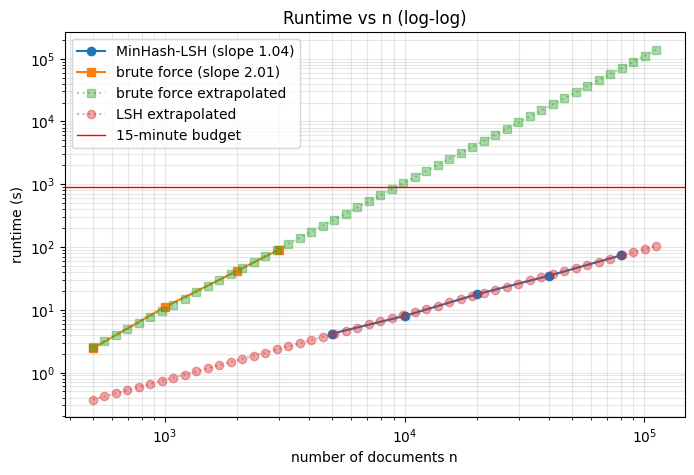

empirical exponent (LSH) = 1.040; brute force = 2.014
brute force extrapolated to n=112,571: 38.7 hours
brute force reaches 15 min at n ~ 9,209

stage times at n=40,000 (s): {'shingle': 22.86, 'minhash': 12.13, 'lsh': 0.16, 'verify': 0.06, 'total': 35.21}
stats at n=40,000: {'n_shingles': 26846677, 'n_candidates': 2094, 'biggest_bucket': 23, 'n_pairs': 856}


In [11]:
ns = np.array([r[0] for r in scale_rows]); ts = np.array([r[1] for r in scale_rows])
bn = np.array([r[0] for r in bf_rows]);   bt = np.array([r[1] for r in bf_rows])
slope, icpt = np.polyfit(np.log10(ns), np.log10(ts), 1)
bslope, bicpt = np.polyfit(np.log10(bn), np.log10(bt), 1)

plt.figure(figsize=(8, 5))
plt.loglog(ns, ts, 'o-', label=f"MinHash-LSH (slope {slope:.2f})")
plt.loglog(bn, bt, 's-', label=f"brute force (slope {bslope:.2f})")
xx = np.logspace(np.log10(500), np.log10(112_571), 50)
plt.loglog(xx, 10**(bicpt) * xx**bslope, 's:', alpha=.4, label="brute force extrapolated")
plt.loglog(xx, 10**(icpt) * xx**slope, 'o:', alpha=.4, label="LSH extrapolated")
plt.axhline(900, color='r', lw=1, label="15-minute budget")
plt.xlabel("number of documents n"); plt.ylabel("runtime (s)"); plt.grid(alpha=.3, which='both'); plt.legend()
plt.title("Runtime vs n (log-log)"); plt.show()
print(f"empirical exponent (LSH) = {slope:.3f}; brute force = {bslope:.3f}")
print(f"brute force extrapolated to n=112,571: {10**bicpt * 112_571**bslope / 3600:.1f} hours")
print(f"brute force reaches 15 min at n ~ {(900 / 10**bicpt) ** (1 / bslope):,.0f}")
print("\nstage times at n=40,000 (s):", {k: round(v, 2) for k, v in stage_at.items()})
print("stats at n=40,000:", stage_stats)

## 6. Written analysis
*n = number of documents, L = average words per document (≈ 670), k = b·r = 100 MinHash functions, b = 20 bands, r = 5 rows, C = number of candidate pairs. All numbers below are from this Colab CPU run.*

**1. Per-stage time and space complexity.**

| Stage | Time | Space |
|---|---|---|
| Shingling (word ids, 5-gram hashes, per-document `np.unique`) | O(nL) for tokenising and hashing + O(nL log L) for sorting each document | O(nL): hash array H (≈ 75M × 8 B ≈ 0.6 GB on the full corpus) + vocabulary |
| MinHash (k vectorised passes + `np.minimum.reduceat`) | O(k · nL) | O(nk) signatures (112,571 × 100 × 8 B ≈ 90 MB) + one O(nL) temporary |
| LSH banding (b sorts of n bucket keys + pair generation) | O(b · n log n + C) | O(n + C) |
| Exact verification (size filter + `np.intersect1d`) | O(C · L) | O(C) |

**2. Bottleneck (measured at n = 40,000, total 35.21 s).**

| Stage | Time (s) | Share |
|---|---|---|
| Shingling | 22.86 | 65 % |
| MinHash | 12.13 | 34 % |
| LSH banding | 0.16 | 0.5 % |
| Verification | 0.06 | 0.2 % |

Shingling is the bottleneck because it contains the only Python-level loop (mapping every word to an integer id with a dictionary, about 27M words at n = 40,000). MinHash is second: 100 passes over 26.8M shingle hashes. Candidate generation and verification are negligible because only C = 2,094 pairs are examined, against 8 × 10⁸ pairs for brute force.

**3. Empirical slope vs theory.** Runtimes for n = 5k, 10k, 20k, 40k, 80k were 4.19, 7.95, 17.61, 34.73 and 73.67 s (median of 2 runs). The log-log fit gives an **empirical exponent of 1.040**, matching the theoretical O(n) for the two dominant stages (their cost is proportional to the total number of words nL). The small excess over 1.0 is explained by the O(b · n log n) sort, the word dictionary growing with n (more cache misses), and the candidate count C growing faster than n (54 → 8,393), because larger prefixes contain both members of more planted duplicate pairs. Since C stays tiny, that does not change the overall linear behaviour. The full corpus (n = 112,571) took **101.7 s**, far below the 15-minute limit.

**4. Boilerplate.** Thousands of unrelated articles share the same long header and footer. In an exact or inverted-index approach, every boilerplate shingle has a posting list thousands of documents long, so the work grows quadratically with the size of that group. With MinHash a pair lands in the same bucket only if all r = 5 minimums in a band agree, probability ≈ J⁵ per band. For boilerplate-sharing but unrelated articles (J ≈ 0.2–0.4), P(examined) = 1 − (1 − J⁵)²⁰ is only ≈ 0.5–10 %, and the measured dev curve confirms it (0.5 % at J ≈ 0.22, 1.9 % at J ≈ 0.33). The few such pairs that become candidates are removed by exact verification (222 of 563 dev candidates were rejected, including near-misses at J = 0.799). Bucket sizes stay small: the largest bucket at n = 40,000 had 23 documents, so no bucket explodes into a quadratic number of pairs.

**5. Brute force.** All-pairs exact comparison makes n(n−1)/2 comparisons, each costing O(L) set intersection: **O(n² L)** time. Measured: 2.43 s at n = 500, 11.12 s at 1,000, 41.61 s at 2,000 and 91.14 s at 3,000, with a fitted **slope of 2.014** (quadratic). Extrapolated, it reaches the 15-minute budget at **n ≈ 9,200** and would need **≈ 38.7 hours** for the full 112,571 documents. At every tested size, my method returned exactly the same pairs as brute force.

**Correctness summary (dev set).** Precision = 1.0000, recall = 1.0000, F1 = 1.0000 (341 of 341 true pairs, 0 missed, 0 wrong), so there are no missed or wrong pairs to explain. The hardest negatives (J = 0.7992, 0.7990, 0.7986) were examined and correctly rejected by exact verification.


## 7. Timer cell: full run and submission
This is the **last cell** and the **only** place where `find_similar_pairs` is called on the full corpus (112,571 documents).
It times exactly one call, then writes `submission.csv` (columns `id1,id2`, `id1 < id2`, no duplicate rows).
*No official timer cell was provided in the handout files, so this cell does the same job: it times one call to the main function on the full data.*

In [ ]:
# ================= TIMER CELL: do not edit =================
import time, resource
ids, texts = docs["id"].tolist(), docs["text"].tolist()

_t0 = time.perf_counter()
pairs = find_similar_pairs(ids, texts, threshold=0.8)
runtime = time.perf_counter() - _t0

print(f"Documents          : {len(ids):,}")
print(f"Pairs found        : {len(pairs):,}")
print(f"TOTAL RUNTIME      : {runtime:.1f} s  ({runtime / 60:.2f} min)   limit: 15 min")
print(f"Peak memory (RSS)  : {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2:.2f} GB   limit: 12 GB")

sub = pd.DataFrame(sorted(pairs), columns=["id1", "id2"])
assert (sub.id1 < sub.id2).all() and not sub.duplicated().any()
sub.to_csv("submission.csv", index=False)
print(f"submission.csv written: {len(sub):,} rows")
print(sub.head())